# 03 · Unsupervised analysis: PCA, K-Means clustering and Apriori
These complement the supervised model and cover the remaining course algorithms.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from kiranbazaar import config as C, features as F
FIG = C.FIG_DIR; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", palette="deep"); plt.rcParams["figure.dpi"] = 110
pd.set_option("display.width", 160, "display.max_columns", 40)

In [2]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
lab = F.labelled(F.build_features(*F.load_raw()))
tr, va, te = F.time_split(lab)

## 1. PCA on the numeric features (fitted on the training set only)

components for 90% variance: 10


,PC1,PC2,PC3
ma_ratio_12,0.35,-0.10,0.11
ma_ratio_3,0.35,-0.11,-0.18
ret_2,0.34,-0.11,-0.10
ret_3,0.33,-0.10,-0.01
ret_6,0.30,-0.10,0.15
ret_1,0.30,-0.08,-0.17
nat_ret_1,0.29,-0.06,-0.16
ret_12,0.28,-0.06,0.25


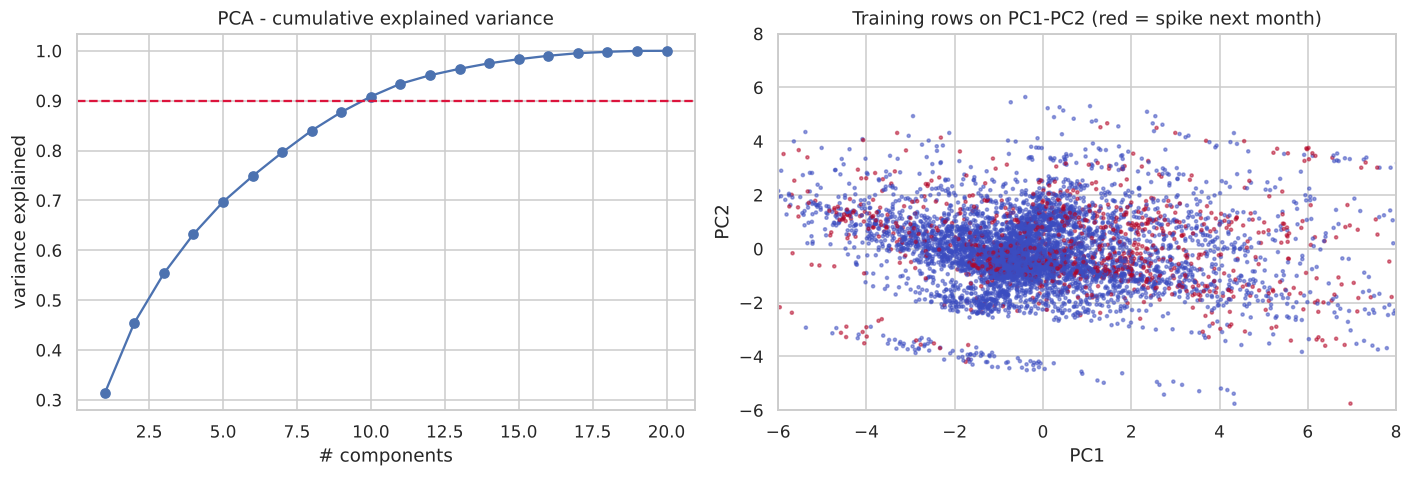

In [3]:
num = [c for c in C.NUMERIC_FEATURES if c not in ("latitude", "longitude")]
imp, sc = SimpleImputer(strategy="median").fit(tr[num]), None
Xtr = imp.transform(tr[num]); sc = StandardScaler().fit(Xtr); Z = sc.transform(Xtr)
pca = PCA().fit(Z)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ax[0].plot(np.arange(1, len(num) + 1), np.cumsum(pca.explained_variance_ratio_), marker="o")
ax[0].axhline(0.9, color="crimson", ls="--"); ax[0].set(title="PCA - cumulative explained variance", xlabel="# components", ylabel="variance explained")
P = pca.transform(Z)[:, :2]
s = ax[1].scatter(P[:, 0], P[:, 1], c=tr[C.TARGET_CLF], cmap="coolwarm", s=4, alpha=0.5)
ax[1].set(title="Training rows on PC1-PC2 (red = spike next month)", xlabel="PC1", ylabel="PC2", xlim=(-6, 8), ylim=(-6, 8))
fig.tight_layout(); fig.savefig(FIG / "20_pca.png")
print("components for 90% variance:", int(np.argmax(np.cumsum(pca.explained_variance_ratio_) >= 0.9) + 1))
pd.DataFrame(pca.components_[:3].T, index=num, columns=["PC1", "PC2", "PC3"]).round(2).sort_values("PC1", key=abs, ascending=False).head(8)

PC1 is a "momentum" axis: all the return and moving-average-ratio features load on it with similar weights. It takes 10 components to keep 90 % of the variance,
and spikes and non-spikes overlap heavily in the PC1-PC2 plane, so the class signal is not concentrated in a few linear directions.
Compare `PCA + Logistic Regression` with plain Logistic Regression in notebook 02.
## 2. K-Means: which market-commodity series behave alike?
Each of the 65 series (5 cities × 13 staples) is described by its **volatility profile** on training data.

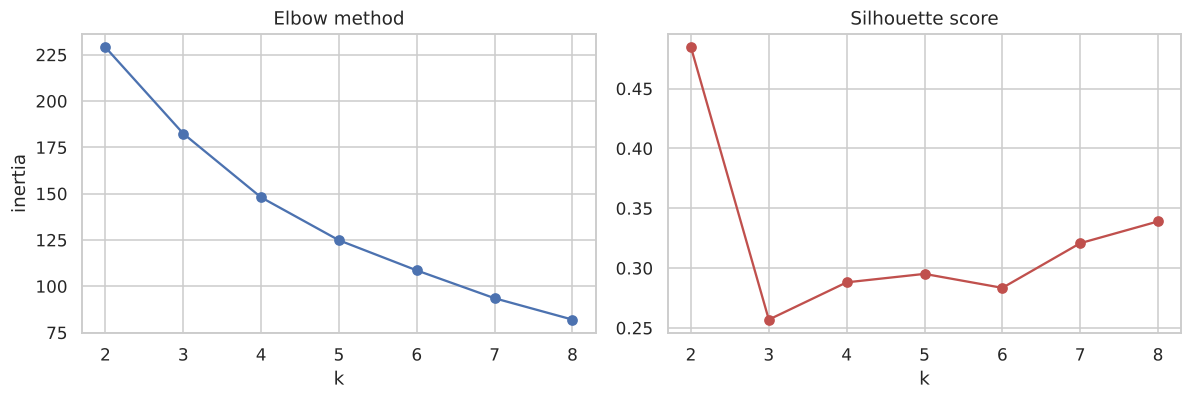

In [4]:
g = tr.groupby(["market", "commodity"])
prof = pd.DataFrame({"mean_change": g.ret_1.mean(), "volatility": g.ret_1.std(), "spike_rate": g[C.TARGET_CLF].mean(),
                     "skew": g.ret_1.skew(), "mean_nat_gap": g.nat_gap.mean(), "fx_corr": g.apply(lambda d: d.ret_1.corr(d.fx_ret_1))}).dropna()
Zp = StandardScaler().fit_transform(prof)
ks = range(2, 9); inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=20, random_state=42).fit(Zp); inertia.append(km.inertia_); sil.append(silhouette_score(Zp, km.labels_))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(ks, inertia, marker="o"); ax[0].set(title="Elbow method", xlabel="k", ylabel="inertia")
ax[1].plot(ks, sil, marker="o", color="#c0504d"); ax[1].set(title="Silhouette score", xlabel="k")
fig.tight_layout(); fig.savefig(FIG / "21_kmeans_k.png")

,mean_change,volatility,spike_rate,skew,mean_nat_gap,fx_corr
cluster,,,,,,
0,0.008,0.047,0.131,0.918,-0.012,0.256
1,0.015,0.134,0.366,0.250,0.000,0.064
2,0.006,0.039,0.113,-0.209,0.031,0.065
3,0.008,0.033,0.084,2.152,-0.006,0.100


cluster 0: ['Beans(mash)', 'Lentils (masur)', 'Lentils (moong)', 'Rice (basmati, broken)', 'Rice (coarse)', 'Wheat', 'Wheat flour']
cluster 1: ['Eggs', 'Poultry']
cluster 2: ['Beans(mash)', 'Lentils (moong)', 'Milk', 'Rice (basmati, broken)', 'Rice (coarse)', 'Sugar']
cluster 3: ['Ghee (artificial)', 'Milk', 'Oil (cooking)', 'Rice (coarse)', 'Wheat', 'Wheat flour']


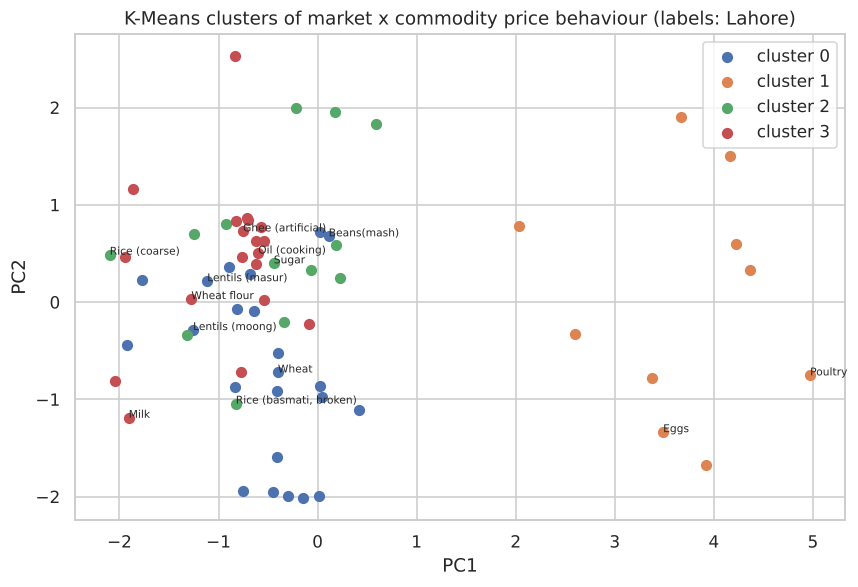

In [5]:
k = 4
km = KMeans(k, n_init=20, random_state=42).fit(Zp)
prof["cluster"] = km.labels_
display(prof.groupby("cluster").mean().round(3))
for c in range(k):
    print(f"cluster {c}:", sorted(set(prof[prof.cluster == c].index.get_level_values("commodity"))))
P2 = PCA(2).fit_transform(Zp)
fig, ax = plt.subplots(figsize=(8, 5.5))
for c in range(k):
    m = prof.cluster.values == c; ax.scatter(P2[m, 0], P2[m, 1], s=40, label=f"cluster {c}")
for (mk, cm), (x, y) in zip(prof.index, P2):
    if mk == "Lahore": ax.annotate(cm, (x, y), fontsize=7)
ax.set(title="K-Means clusters of market x commodity price behaviour (labels: Lahore)", xlabel="PC1", ylabel="PC2"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "22_kmeans_clusters.png")

Interpretation (read the cluster means table above):
* **Volatile perishables** (Eggs, Poultry in every city): ~3× higher volatility and spike rate than anything else.
* **FX-sensitive series** (highest correlation with the rupee): daals, rice and wheat in most cities.
* **Rare-jump series** (high positive skew): flat most months, then a big step. Ghee and cooking oil (administered / import-priced) fall here, plus wheat and milk in some cities.
* **Stable series** (lowest skew): milk, sugar and some daal/rice series.

Apart from poultry and eggs, the same staple falls into **different clusters in different cities** (e.g. coarse rice appears in three clusters).
Local market behaviour matters, which is why `market` and the city-vs-national gap `nat_gap` are model features.
## 3. Apriori: which staples spike together?
Each (market, month) is a "basket" whose items are the staples that spiked (>5 %) that month. Association rules show co-movement.

In [6]:
from mlxtend.frequent_patterns import apriori, association_rules
feats = F.build_features(*F.load_raw())
basket = (feats.assign(spike=feats.ret_1 > C.SPIKE_THRESHOLD).pivot_table(index=["market", "date"], columns="commodity", values="spike", aggfunc="max")
          .dropna(thresh=10).fillna(False).astype(bool))
basket = basket[basket.any(axis=1)]
print("baskets (market-months with >=1 spike):", len(basket))
freq = apriori(basket, min_support=0.05, use_colnames=True)
rules = association_rules(freq, metric="lift", min_threshold=1.2)
rules = rules[(rules.confidence >= 0.4)].sort_values("lift", ascending=False)
rules["antecedents"] = rules.antecedents.apply(lambda s: ", ".join(sorted(s))); rules["consequents"] = rules.consequents.apply(lambda s: ", ".join(sorted(s)))
rules[["antecedents", "consequents", "support", "confidence", "lift"]].head(12).round(3)

baskets (market-months with >=1 spike): 588


,antecedents,consequents,support,confidence,lift
7,Ghee (artificial),Oil (cooking),0.075,0.746,6.960
6,Oil (cooking),Ghee (artificial),0.075,0.698,6.960
12,"Beans(mash), Lentils (moong)",Lentils (masur),0.051,0.625,4.537
14,"Lentils (masur), Lentils (moong)",Beans(mash),0.051,0.750,4.083
23,"Eggs, Wheat",Wheat flour,0.056,0.600,3.459
13,"Beans(mash), Lentils (masur)",Lentils (moong),0.051,0.600,3.425
1,Lentils (masur),Beans(mash),0.085,0.617,3.361
0,Beans(mash),Lentils (masur),0.085,0.463,3.361
22,"Eggs, Wheat flour",Wheat,0.056,0.600,2.990
10,Wheat flour,Wheat,0.099,0.569,2.833


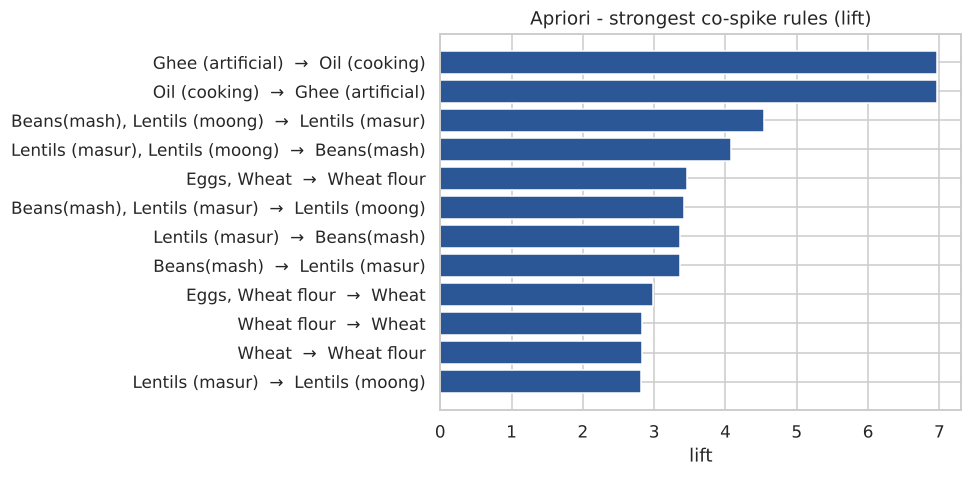

In [7]:
top = rules.head(12)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(top.antecedents + "  →  " + top.consequents, top.lift, color="#2b5797"); ax.invert_yaxis()
ax.set(title="Apriori - strongest co-spike rules (lift)", xlabel="lift"); fig.tight_layout(); fig.savefig(FIG / "23_apriori_rules.png")

The strongest rule is **ghee ↔ cooking oil** (lift ≈ 7: both depend on imported palm oil), then the **three daals** (masoor, moong, mash) and
**wheat ↔ wheat flour** (same supply chain). That supports the cross-commodity `basket_ret_1` feature and is useful in itself: when wheat
jumps, households should expect atta to follow.